In [2]:
# Libs
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Procura o utils.py subindo pela árvore de diretórios
repo_root = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(repo_root))

from utils import LinearRegression, MSE, GradientDescent, OLS

# Importar os dados
df = pd.read_csv(r'../../aulas/datasets/NHANES-2017-2018-height-weight.csv')
df.drop(columns=['Unnamed: 0'], inplace=True)


*Este notebook é uma Cola e não é uma amostra do estado final da Aula01.ipynb, mas contém as bases tanto para a Aula01.ipynb quanto o material as funções da aula.*    
*Lembrando que o notebook é uma versão resumida criada para complementar a aula, ou seja, ele sozinho pdoe ser insuficiente.*

# Bloco 1 - Introdução a Ciência de Dados e a Limpeza de Dados

## Apresentação

*(Introdução ao Curso, incluindo a ementa, abordagem matemática, etc.)*  
Parte matemática introduzir assim:  

A Ciência de Dados como disciplina teórica requer uma matemática de nível de graduação, principalmente para as disciplinas da Álgebra Linear e Estatística para a manipulação dos dados e dos modelos, e noções de Cálculo para o entendimento de como os modelos 'aprendem' e são treinados. No entanto, neste curso, decidimos simplificar ao máximo as bases matemáticas dos modelos mas sem anular completamente a matemática, tão presente no dia a dia do cientista. Assim, fica implícito, e e muitos casos apenas como referência auxiliar, a matemática mais formal que baseia a área, e espera-se do aluno que deseja seguir na área estude essas áreas, ou siga as dicas recomendadas no material de `proximos-passos.md`.

## O que é Ciência de Dados? + Diferenças das demais áreas de Dados

A Ciência de Dados é uma área situada na interseção entre 3 diferentes áreas ou ramos do conhecimento: a Matemática, a Metodologia Científica, e a Programação. De modo geral, o Cientista de Dados se preocupa em trabalhar com dados e informações na finalidade de transformar esses dados em ações cabíveis de serem tomadas, frequentemente envolvendo criação de *modelos preditivos* e *modelos de Inteligência Artificial* pensados em tentar prever o futuro com base no passado.

Ou seja, o Cientista de Dados ajuda na tomada de decisão ao fornecer as ferramentas e as análises necessárias não apenas para *compreender os dados* e *entender o que eles significam* contextualizados, mas também é capaz de *criar algoritmos e métodos que atuam sobre os dados* para prever valores, classificar clientes, estipular riscos, recomendar produtos, entre várias outras. Todas as tarefas abaixo descritas são, por exemplo, cabíveis de serem uma tarefa para um cientista de dados:

- Criar dashboards capazes de traduzir informações do passado e do presente de forma inteligente e dinâmica;
- Costruir um modelo que ajuda a estipular o faturamento da empresa ao longo do tempo;
- Classificar e segmentar clientes entre perfis de risco e de compra, para adotar políticas específicas para cada grupo de cliente;
- Criar um algoritmo capaz de recomendar os melhores produtos dado o perfil do cliente;
- Criar um algoritmo que automaticamente extrair informações de imagens enviadas;
- Computa a potencial mudança nos cliques que uma eventual decisão de design no site podem trazer;

entre outros.

### Analista de Dados ou Cientista de Dados?
Muito se confunde sobre quais são de fato as responsabilidades de um *Cientista de Dados* em constraste com a de um *Analista de Dados*. Esta distinção é ainda mais borrada pelo fato de que muitas empresas não distinguem as duas áreas como separadas. Mas, via de regra, o Cientista de dados é um *Analista de Dados especializado*, com formação mais ampla e adequada para a construção de modelos de aprendizado de máquina e tratamento estatístico mais rigoroso. Além disso, o Cientista de Dados frequentemente está lidando com problemas relacionados *ao futuro*, como planejamento de vendas e previsão de risco, enquanto os analistas de dados costumam focar no passado e presente dos dados.

## Tipos de Aprendizado de Máquina

Existem vários tipos diferentes de aprendizado de máquina, dos quais podemos apontar como os dois mais importantes e principais os modelos de **Regressão** e os modelos de **Classificação**. Outros tipos de modelo existem e podem ser aprofundados.

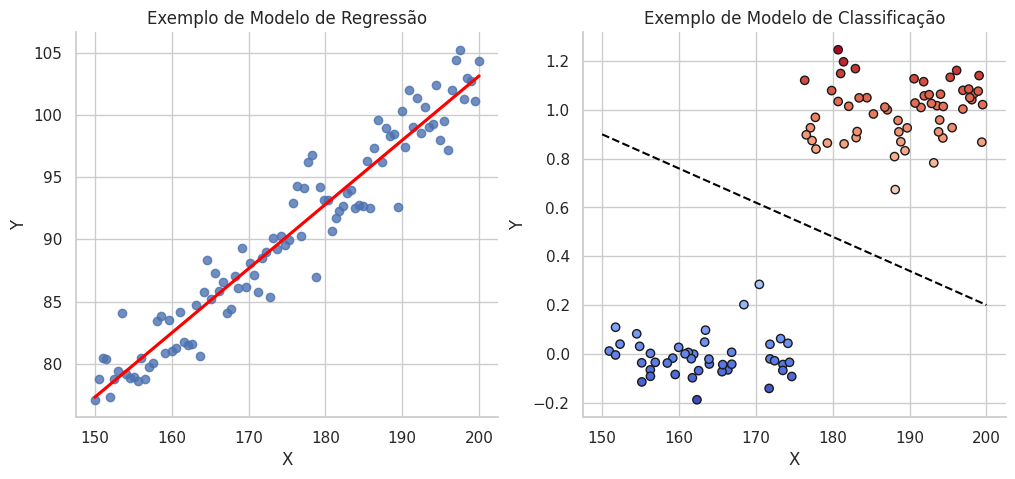

In [ ]:
# Exemplo de modelos de ML ilustrativos

# Criar dados de exemplo para regressão linear e SVM
reg_x = np.linspace(150, 200, 100).reshape(-1, 1)
reg_y = 0.5 * reg_x + 3 + np.random.normal(0, 2, size=reg_x.shape)
svm_x = np.random.uniform(150, 200, size=(100, 1))
svm_y = (svm_x > 175).astype(int).ravel() + np.random.normal(0, 0.1, size=svm_x.shape[0])

plt.subplots(1, 2, figsize=(12, 5))

# Gráfico de regressão linear
plt.subplot(1, 2, 1)
sns.regplot(x=reg_x.ravel(), y=reg_y.ravel(), ci=None, line_kws={"color": "red"})
plt.title('Exemplo de Modelo de Regressão')
plt.xlabel('X')
plt.ylabel('Y')
sns.despine()

# Gráfico de SVM
plt.subplot(1, 2, 2)
plt.scatter(svm_x, svm_y, c=svm_y, cmap='coolwarm', edgecolor='k')
sns.lineplot(x=[150, 200], y=[0.9, 0.2], color='black', linestyle='--')
plt.title('Exemplo de Modelo de Classificação')
plt.xlabel('X')
plt.ylabel('Y')
sns.despine()


## Outras áreas de Dados

# ...

# O que é linearidade?
Linearidade é um conceito estudado na disciplina de Álgebra Linear, cuja amplitude total do tema não pertence ao escopo deste curso. Neste tópico, pretendemos introduzir uma abordagem intuitiva ao conceito que nos servirá como base para os tópicos seguintes. Observemos o seguinte gráfico, que mostra os valores de y (eixo vertical) para uma certa variável x (eixo horizontal). O gráfico está *incompleto*, pois está representando apenas os primeiros valores de x.

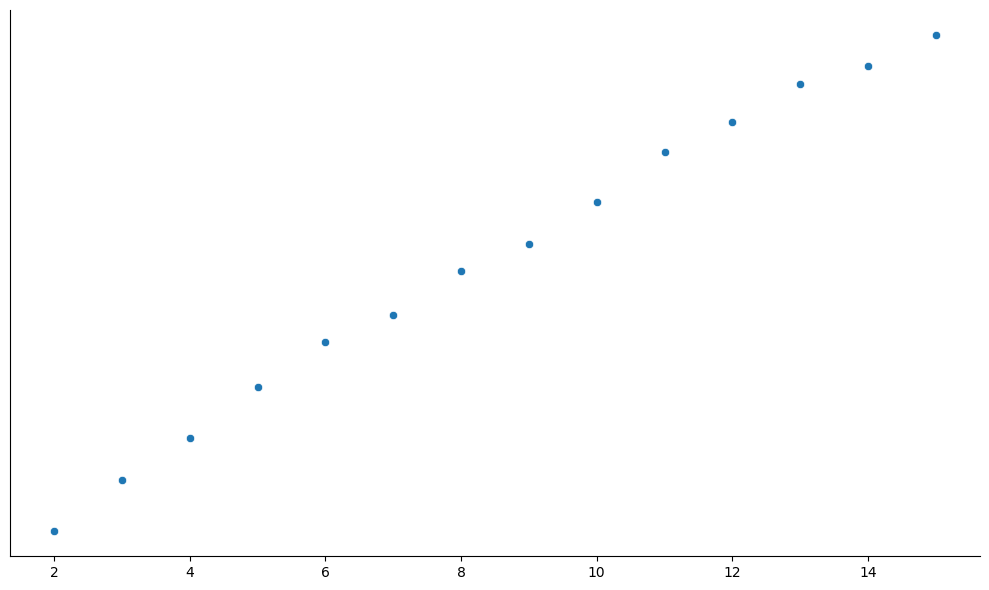

In [3]:
# Criar dados medianos
mediana_altura = df.groupby('age')['height'].median()

# Gráfico da mediana de altura apenas com X <= 15

plt.figure(figsize=(10, 6))
sns.scatterplot(x=mediana_altura[mediana_altura.index <= 15].index, y=mediana_altura[mediana_altura.index <= 15].values, marker='o')

# Esconder nome do titulo e dos eixos x e y
plt.title('')
plt.xlabel('')
plt.ylabel('')

# Esconder labels dos eixos
plt.yticks([])

sns.despine()
plt.tight_layout()
plt.show()

Analisando apenas este intervalo limitado de valores, parece claro deduzir que esta distribuição pode ser representada por uma reta ou *relação linear* entre seus dados, já que claramente existe uma tendência de que, a medida em que se aumenta o x, aumenta-se o y. Podemos associar a esta relação uma *reta* que relaciona valores de X para valores de Y. Os detalhes em como essa regra pode ser criada ficarão para os próximos tópicos: por enquanto, vamos apenas considerar que nós traçamos uma reta representando esse crescimento linear nos dados em Y com relação ao X.

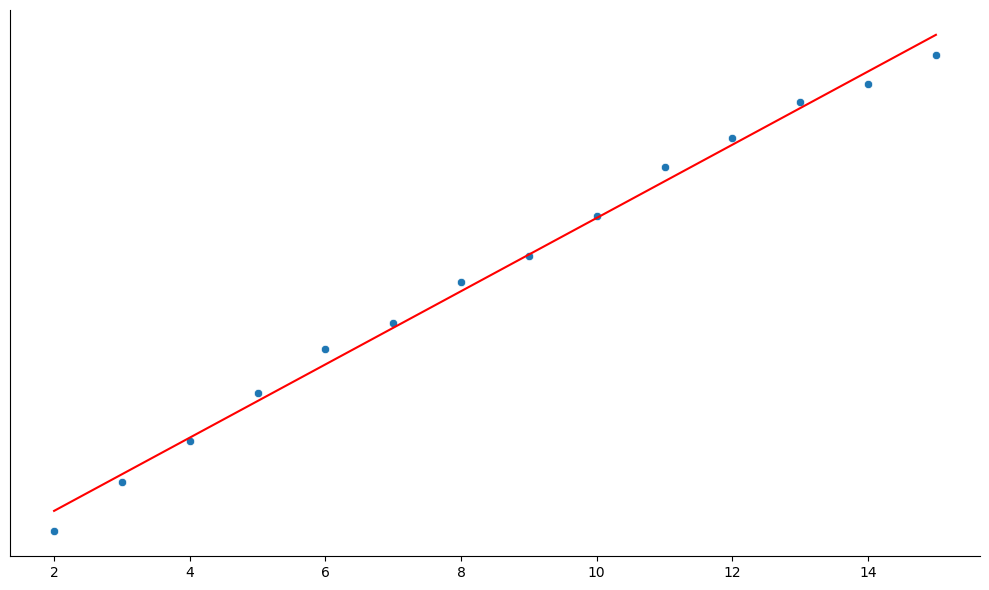

In [4]:
# Criar uma regressão linear ols APENAS para os dados X <= 15 e plotar a reta

x = mediana_altura[mediana_altura.index <= 15].index.values.reshape(-1, 1) # reshape para transformar em array 2D
y = mediana_altura[mediana_altura.index <= 15].values.reshape(-1, 1)

model = LinearRegression()
ols = OLS()
model = ols.fit(model, x, y)
y_pred = model.predict(x)

# Plotar a reta
plt.figure(figsize=(10, 6))
sns.scatterplot(x=x.flatten(), y=y.flatten(), marker='o')
plt.plot(x, y_pred, color='red')

# Esconder nome do titulo e dos eixos x e y
plt.title('')
plt.xlabel('')
plt.ylabel('')

# Esconder labels dos eixos
plt.yticks([])

sns.despine()
plt.tight_layout()
plt.show()

De fato, essa reta parece representar muito bem o conjunto dos dados. Observe que essa reta funciona como uma espécie de "predição" do valor de y: a medida em que X aumenta, Y aumenta, assim como a reta, e podemos usar essa informação ao nosso favor *extrapolando a reta*, que possui uma função matemática bem definida, e vendo que valor a reta nos daria para um X maior, como por exemplo, X = 80:

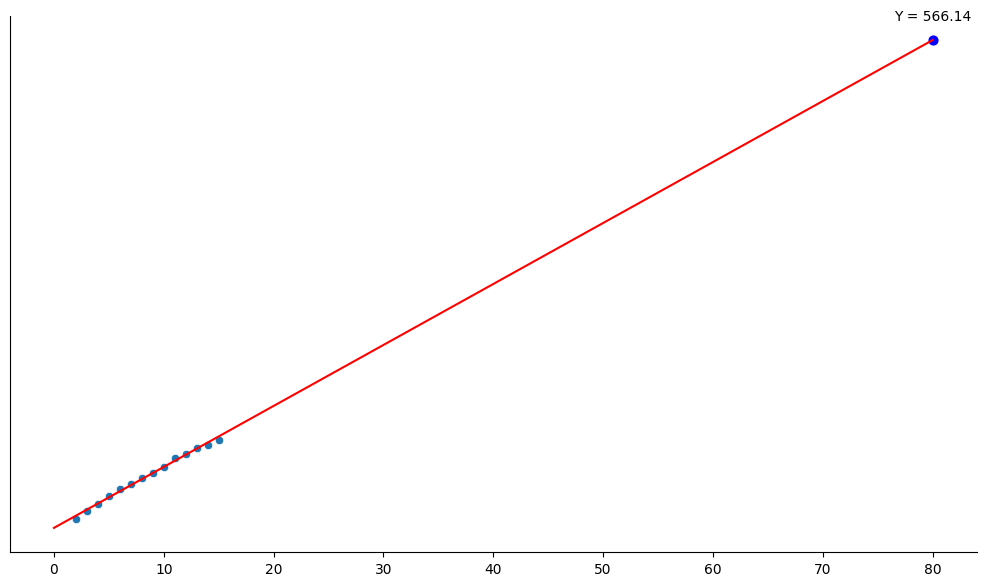

In [5]:
# Plotar gráfico extrapolado até o X = 80, usando a reta da regressão OLS treinada apenas com os dados X <= 15

x_estrapolado = np.arange(0, 81).reshape(-1, 1)
y_estrapolado = model.predict(x_estrapolado)
y_80 = model.predict(np.array([[80]]))
y_80_valor = y_80.item()

# Plotar a reta extrapolada
plt.figure(figsize=(10, 6))
sns.scatterplot(x=x.flatten(), y=y.flatten(), marker="o")
plt.plot(x_estrapolado.flatten(), y_estrapolado.flatten(), color="red")

# Exibir o ponto X = 80
plt.scatter(80, y_80_valor, color="blue", s=40, label=f"Y(80) = {y_80_valor:.2f}")

# Texto acima do ponto
plt.annotate(f"Y = {y_80_valor:.2f}", xy=(80, y_80_valor), xytext=(0, 12), textcoords="offset points", ha="center", va="bottom")

plt.title("")
plt.xlabel("")
plt.ylabel("")
plt.yticks([])
sns.despine()
plt.tight_layout()
plt.show()

Ou seja, usando essa reta que encontramos para os dados até X = 15, ocultando todos os demais, construimos uma reta capaz de nos dar uma espécie de *previsão* para o valor de Y quando X=80, que é de $566,14$. Agora, vamos visualizar o significado real de cada eixo, e por fim, o conjunto completo dos dados, e comparar com nossas previsões analisando aquele pequeno conjunto dos dados.

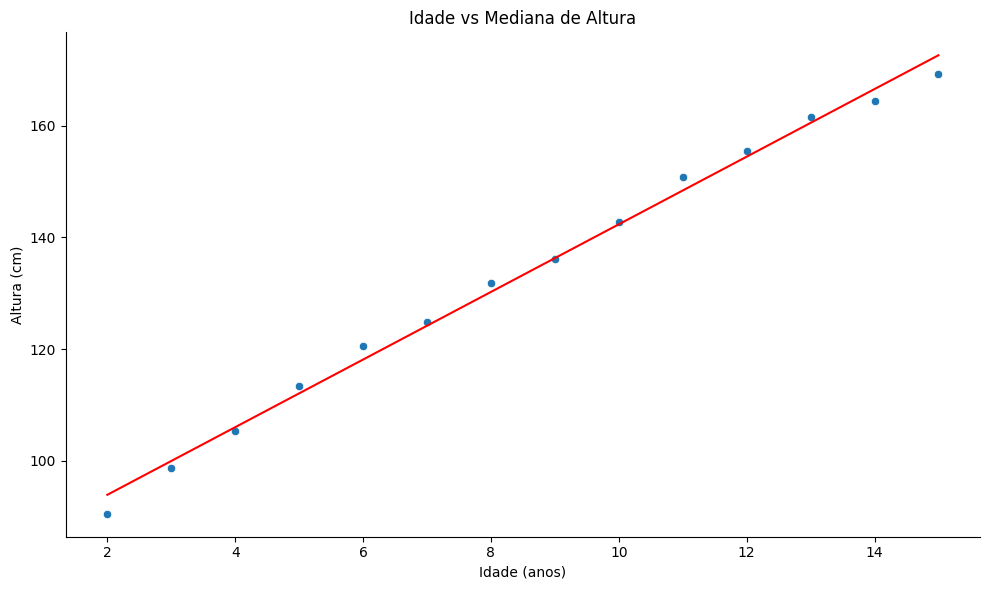

In [6]:
# Mesmo gráfico, mas com nome nos eixos

# Plotar a reta
plt.figure(figsize=(10, 6))
sns.scatterplot(x=x.flatten(), y=y.flatten(), marker='o')
plt.plot(x, y_pred, color='red')

# Esconder nome do titulo e dos eixos x e y
plt.title('Idade vs Mediana de Altura')
plt.xlabel('Idade (anos)')
plt.ylabel('Altura (cm)')

sns.despine()
plt.tight_layout()
plt.show()

Agora com os eixos revelados, faz sentido ainda pensar que a relação entre idade e altura é linear? Isto é, faz sentido a ideia de que, a medida em que a idade aumenta, aumenta-se cada vez mais a altura?
Isso parece longe da verdade. De fato, ao exibirmos a verdadeira distribuição dos dados em comparação com a reta que criamos:

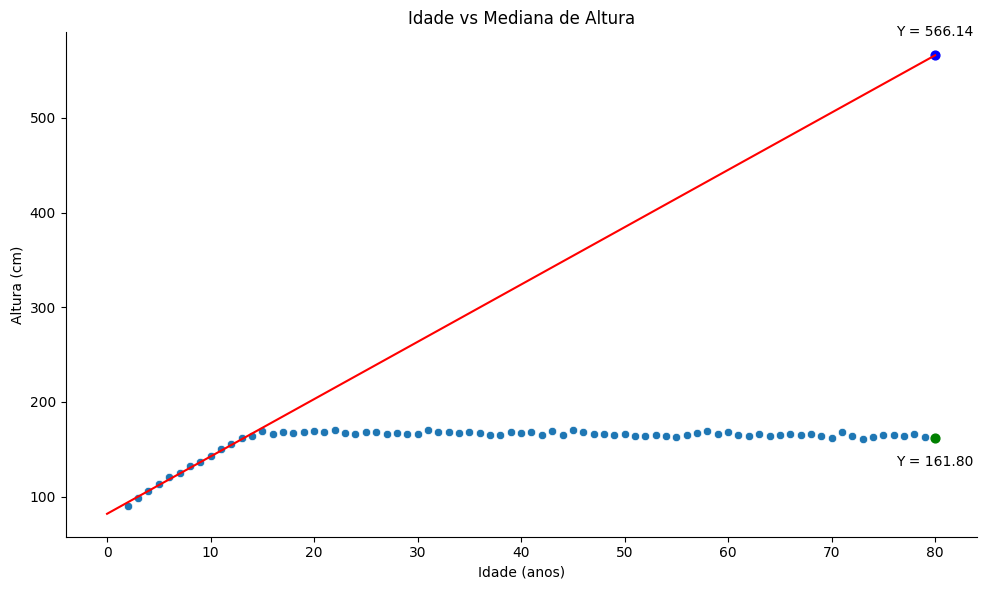

In [7]:
# Gráfico completo com a reta prevista para X <= 15.
y_80 = mediana_altura[mediana_altura.index == 80].item()

plt.figure(figsize=(10, 6))
sns.scatterplot(x=mediana_altura.index, y=mediana_altura.values, marker='o')
sns.lineplot(x=x_estrapolado.flatten(), y=y_estrapolado.flatten(), color='red')
plt.scatter(80, y_80_valor, color="blue", s=40, label=f"Y(80) = {y_80_valor:.2f}")
plt.annotate(f"Y = {y_80_valor:.2f}", xy=(80, y_80_valor), xytext=(0, 12), textcoords="offset points", ha="center", va="bottom")
plt.scatter(80, y_80, color="green", s=40, label=f"Y(80) = {y_80:.2f}")
plt.annotate(f"Y = {y_80:.2f}", xy=(80, y_80), xytext=(0, -12), textcoords="offset points", ha="center", va="top")

plt.xlabel('Idade (anos)')
plt.ylabel('Altura (cm)')

sns.despine()
plt.title('Idade vs Mediana de Altura')
plt.tight_layout()
plt.show()

Podemos ver que nossa previsão errou significantemente quando consideramos apenas o conjunto inicial dos dados, atribuindo um valor de Y = 566, ou *5 metros de altura*, para pessoas com idade próxima a 80. Isto obviamente não pode ser real, e o gráfico mostra um claro padrão na mediana das idades a partir de X = 15-18, onde as pessoas **param de crescer** e portanto, a relação linear que surge nos primeiros pontos de y em relação a X não se mantém válida para os demais pontos de X. 

Este é um excelente exemplo de uma relação **não-linear**, isto é, a relação entre X (idade) e Y (altura) não pôde ser facilmente expressão por meio de uma relação linear entre suas variáveis. Descobrir primeiro um exemplo de uma relação não-linear pode ser útil para entender os limites do que modelos de machine learning lineares, como o que veremos em seguida, podem possuir. 

# Regressão Linear
A Regressão Linear é um modelo de Aprendizado de Máquina, e portanto, se propõe a *prever* valores de Y de saída com base em valores X de entrada, por meio de uma *função linear* entre as variáveis. Intuitivamente, o modelo de Regressão Linear pode ser entendido como uma tentativa de *encaixar uma reta que melhor representa os dados*, mas esta noção intuitiva é limitada para um cenário de apenas uma variável de entrada e uma variável de saída, como predizer a Altura (Y) em função apenas da Idade (X), desconsiderando peso, comprimento e etc.

Durante as aulas desse curso, concentraremos esforços em elaborar e construir um modelo de regressão linear *mais simples*, que possa ser compreendido apenas com noções mais básicas de Geometria Analítica, sem Álgebra Linear. Por isso, nos restringiremos a estudar apenas regressão linear com uma variável de entrada, também chamada de *Single Linear Regression*, mas saiba que o modelo pode receber quantas variáveis de entrada quanto se queira, usando uma notação mais geral que pode ser consultada no material de apoio.

No Ensino Médio, aprende-se que uma reta pode ser representada no plano da seguinte forma:

$\boxed{y = ax +b}$  

com $a$ sendo chamado de *coeficiente angular* e sendo responsável pela inclinação da reta, e *b* sendo chamado de intercepto, onde a reta cruza com o eixo y.  
Experimente substituir os valores de $a$ e de $b$ abaixo para ver a mudança no gráfico.

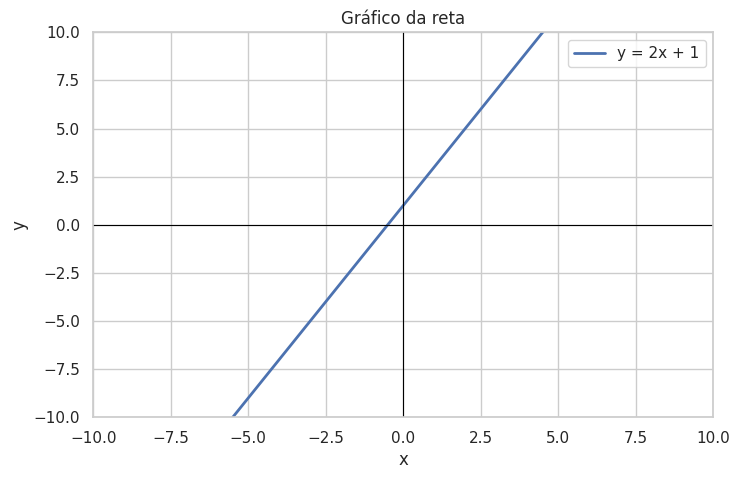

In [8]:
a = 2   # Coeficiente angular (inclinação)
b = 1   # Intercepto (onde a reta cruza o eixo y)

x = np.linspace(-10, 10, 200)
y = a * x + b

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))
plt.plot(x, y, label=f"y = {a}x + {b}", linewidth=2)

plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(0, color="black", linewidth=0.8)

# Limites fixos dos eixos
plt.xlim(-10, 10)
plt.ylim(-10, 10)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Gráfico da reta")
plt.legend()
plt.show()

Dentro desse contexto, podemos facilmente perceber que, como *x* representa os valores que nós temos como "entrada" e *y* o valor previsto pelo modelo, temos duas variáveis que podemos "mexer" para encontrar a melhor reta possível: $a$ e $b$. Várias manerias diferentes poderiam acabar surgindo para representarem a mesma distribuição, então como decidimos a melhor maneira possível?

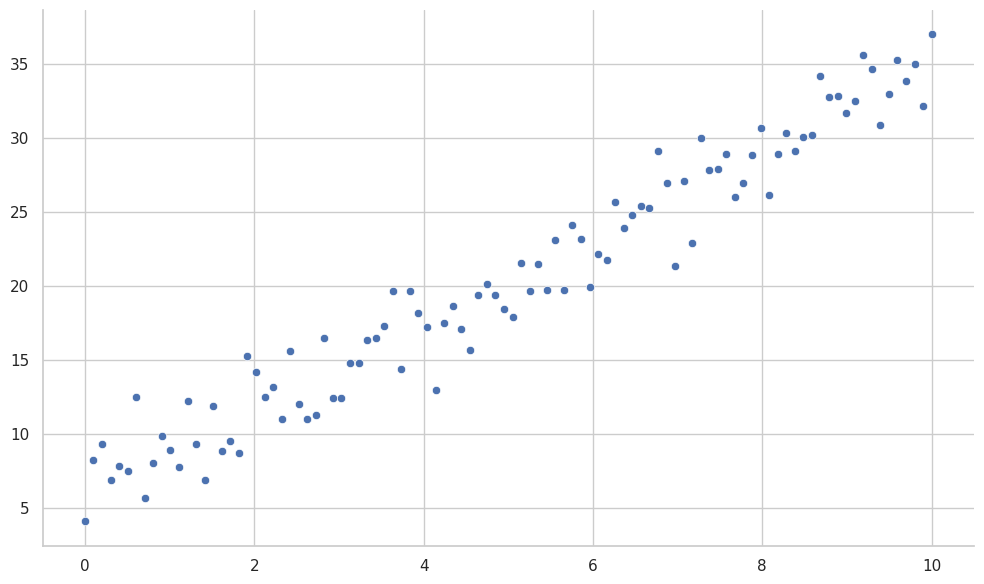

In [9]:
# Gerar dados lineares com ruído gaussiano para representar uma certa relação linear arbitrária

x = np.linspace(0, 10, 100)
y = 3 * x + 5 + np.random.normal(0, 2, size=x.shape)  # y = 3x + 5 + ruído gaussiano

plt.figure(figsize=(10, 6))
sns.scatterplot(x=x, y=y, marker='o')
sns.despine()
plt.tight_layout()
plt.show()

Para definirmos o que significa realmente uma "melhor" reta, precisamos de um *parâmetro*, que nos permita diferenciar diferentes possíveis retas. 

## Função de Custo - Erro Médio Quadrático

O que significa, matematicamente, "melhor"? Para que um computador possa buscar a melhor reta, precisamos transformar essa ideia intuitiva em um **número**, que nos diga quão boa (ou quão ruim) é uma determinada reta. Para isso, utilizaremos o que podemos chamar de **função de custo** (*cost function* ou *loss function*), uma função que *quantifica* quão errado nosso modelo está, e com essa informação, podemos agir para minimizar esses erros.

## MSE - Mean Squared Error

(())

# Derivada

In [10]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

ponto = 0.0
h_valores = np.geomspace(1.8, 0.015, 45)
a_curva = np.linspace(-2, 3, 300)
y_curva = np.array([custo_a(a) for a in a_curva])

def inclinacao_secante(h):
    return (custo_a(ponto + h) - custo_a(ponto)) / h

derivada_aproximada = derivada_numerica = (custo_a(ponto + 1e-5) - custo_a(ponto - 1e-5)) / (2e-5)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(a_curva, y_curva, color='tab:blue', linewidth=2, label='Curva do MSE')
ax.scatter([ponto], [custo_a(ponto)], color='black', zorder=4, label='Ponto escolhido')
secante, = ax.plot([], [], color='tab:orange', linewidth=2.5, label='Secante')
ponto_movel, = ax.plot([], [], 'o', color='tab:orange', markersize=8)
tangente, = ax.plot([], [], '--', color='tab:green', linewidth=2, label='Tangente (limite)')
texto = ax.text(0.03, 0.95, '', transform=ax.transAxes, va='top', fontsize=11)

ax.set_xlim(-2, 3)
ax.set_ylim(-5, 90)
ax.set_xlabel('a (inclinação da reta)')
ax.set_ylabel('MSE')
ax.set_title('A secante se aproxima da tangente quando h tende a zero')
ax.legend()
sns.despine()

def atualizar(frame):
    h = h_valores[frame]
    y0 = custo_a(ponto)
    y1 = custo_a(ponto + h)
    x_linha = np.array([ponto - 0.9, ponto + h + 0.9])
    y_linha = y0 + inclinacao_secante(h) * (x_linha - ponto)
    x_tangente = np.array([ponto - 0.9, ponto + 0.9])
    y_tangente = y0 + derivada_aproximada * (x_tangente - ponto)
    secante.set_data(x_linha, y_linha)
    ponto_movel.set_data([ponto + h], [y1])
    tangente.set_data(x_tangente, y_tangente)
    texto.set_text(f'h = {h:.3f}\ninclinação da secante = {inclinacao_secante(h):.2f}')
    return secante, ponto_movel, tangente, texto

animacao = FuncAnimation(fig, atualizar, frames=len(h_valores), interval=90, blit=True, repeat=True)
plt.close(fig)
display(HTML(animacao.to_jshtml()))


NameError: name 'custo_a' is not defined